# Donor & acceptor curation

Two review passes, meant to be worked through by eye rather than by a blanket rule:

1. **Donor masks** -- every eligible donor crop *large enough to blend cleanly*
   (`min_dim >= 20px`, largest first) for each candidate species, mask boundary outlined,
   plus a sample of the actual rotate/flip augmentations the pipeline would apply.
2. **Acceptor scenes** -- candidate background frames the pipeline could paste onto, sampled
   across the full range of real time your footage covers (not just near-duplicate frames a
   few seconds apart).

Report back which donors (by species + frame number) you'll accept, and which acceptor
frames (by index) to exclude, and that becomes an explicit include/exclude list rather than
a blanket filter.

This notebook imports `blend_review_generate.py` and `blend_review_large_donors.py` from
`copy_paste_species_demo/`. VS Code's Jupyter extension often starts the kernel at the
workspace root rather than the notebook's own folder, so the cell below searches a few
likely spots and adds the right one to `sys.path` before importing -- the same problem (and
the same fix) as `_find_dataset_root()` in `copy_paste_demo.ipynb`.

In [1]:
import os
import random
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


REQUIRED_MODULES = ["blend_review_generate.py", "blend_review_large_donors.py"]


def _find_review_module_dir() -> Path:
    # Order of preference:
    #  1. The notebook's OWN folder. VS Code injects `__vsc_ipynb_file__` (the notebook's path)
    #     into the kernel, so this works no matter where VS Code decided to start the kernel.
    #  2. The kernel's working folder, its copy_paste_species_demo/ subfolder, and parents.
    #  3. The known project location on Tash's Mac.
    # A folder only counts if it has ALL the required modules side by side.
    candidates = []
    nb_file = globals().get("__vsc_ipynb_file__")
    if nb_file:
        candidates.append(Path(nb_file).resolve().parent)
    cwd = Path.cwd()
    candidates += [cwd, cwd / "copy_paste_species_demo"]
    p = cwd
    for _ in range(4):
        p = p.parent
        candidates += [p, p / "copy_paste_species_demo"]
    candidates.append(Path.home() / "Desktop" / "EGH490-2_scripts" / "copy_paste_species_demo")

    for c in candidates:
        if all((c / f).exists() for f in REQUIRED_MODULES):
            return c.resolve()

    raise FileNotFoundError(
        f"Couldn't find a folder containing {REQUIRED_MODULES}.\n"
        f"Kernel working folder: {cwd}\nNotebook file (from VS Code): {nb_file}\n"
        "Checked:\n  " + "\n  ".join(str(c) for c in candidates))


_module_dir = _find_review_module_dir()
print(f"Review module folder resolved to: {_module_dir}")

# Run from the module folder so the PNGs this notebook saves land next to it, not wherever
# the kernel happened to start.
os.chdir(_module_dir)
if str(_module_dir) in sys.path:
    sys.path.remove(str(_module_dir))
sys.path.insert(0, str(_module_dir))

# Drop any cached copies from an earlier run of this cell. Python caches imported modules, so
# without this a stale blend_review_generate from another folder can be silently reused.
for _m in ("blend_review_generate", "blend_review_large_donors"):
    sys.modules.pop(_m, None)

import blend_review_generate as base
from blend_review_large_donors import random_transform

print(f"blend_review_generate loaded from: {Path(base.__file__).resolve()}")

dataset = base.parse_cvat_annotations(base.ANNOTATIONS_XML)
frame_index = base.build_frame_index(base.IMAGES_DIR)
print(f"Parsed {len(dataset)} images. Indexed {len(frame_index)} real frames under {base.IMAGES_DIR}.")

SPECIES_LIST = ["Raccoon Butterflyfish", "Forcepsfish", "Ornate Butterfly Fish", "Moorish Idol", "Convict Tang"]

Review module folder resolved to: <project>/copy_paste_species_demo
blend_review_generate loaded from: <project>/copy_paste_species_demo/blend_review_generate.py
Parsed 2817 images. Indexed 2817 real frames under <project>/full_dataset.


## Part 1: Donor masks -- large only

Poisson/seamless-clone blends badly on small, distant donor crops (colour-attenuation in the
raw footage, confirmed across every blend mode) but cleanly on large ones, so this gallery is
filtered to `min(w, h) >= MIN_DIM_LARGE` and sorted **largest first** -- every eligible donor
that clears that bar, not just a fixed top-N, so there's a real pool to curate from. Mask
boundary outlined in magenta, labelled `#index f<frame> WxH` so a specific one can be reported
back by index or frame number.

Raccoon Butterflyfish: 88/95 eligible donors kept at min_dim>=20px


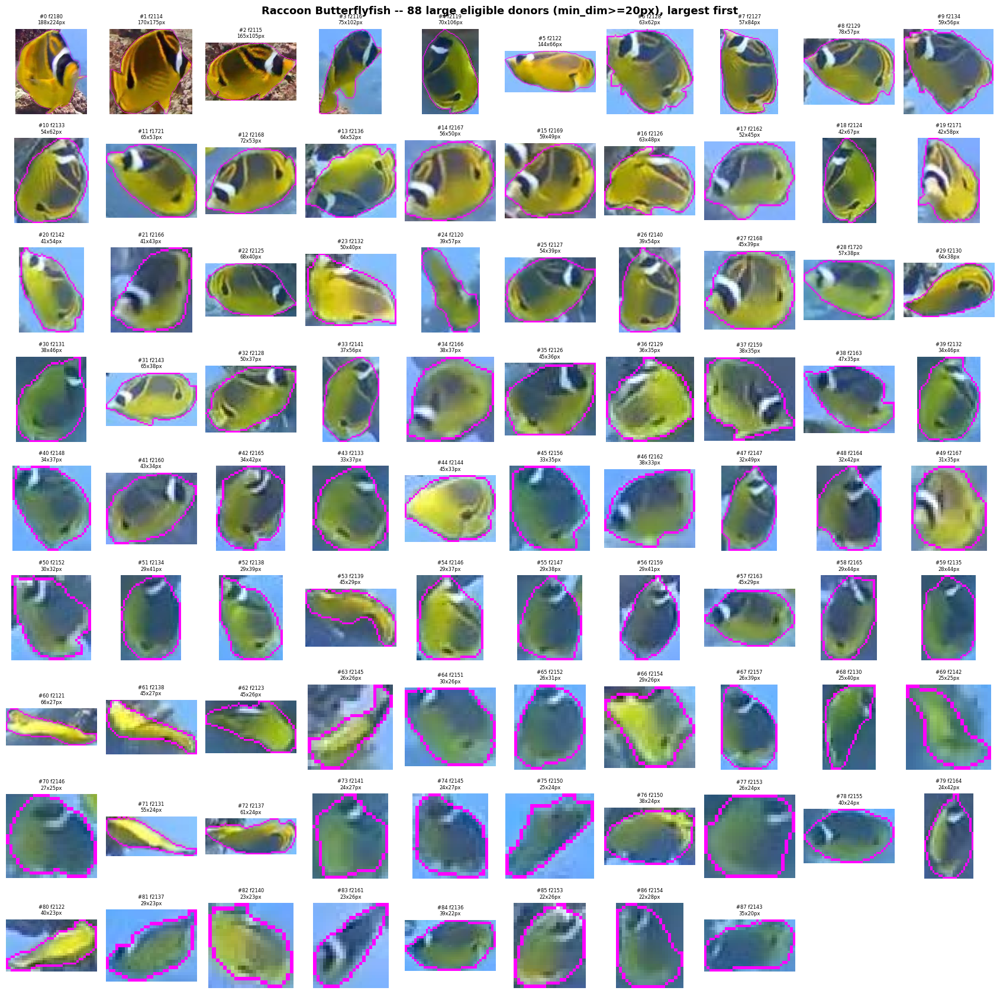

Forcepsfish: 49/82 eligible donors kept at min_dim>=20px


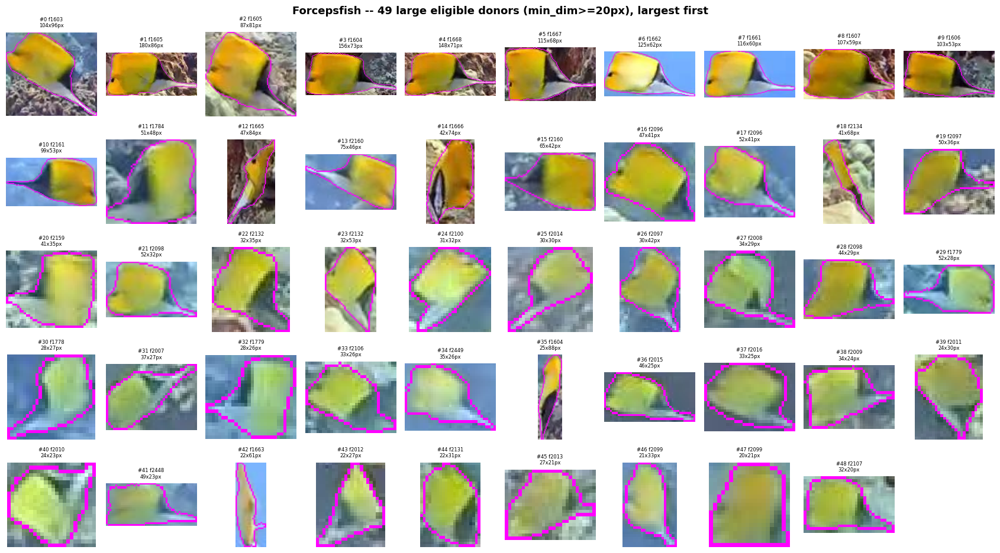

Ornate Butterfly Fish: 68/86 eligible donors kept at min_dim>=20px


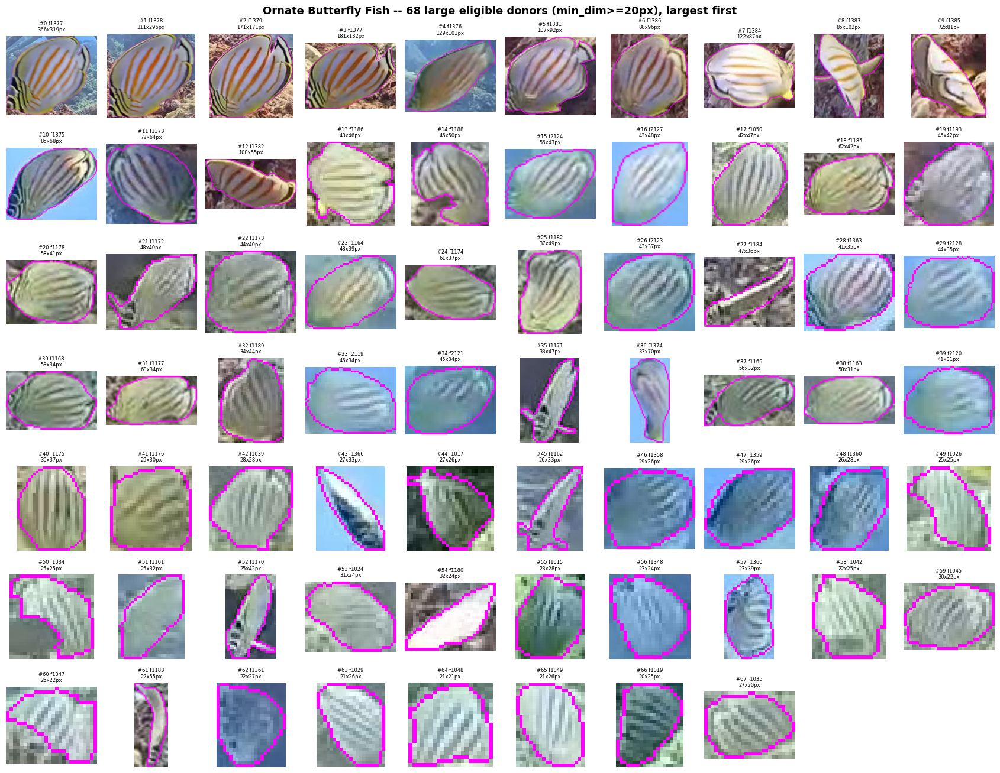

Moorish Idol: 54/135 eligible donors kept at min_dim>=20px


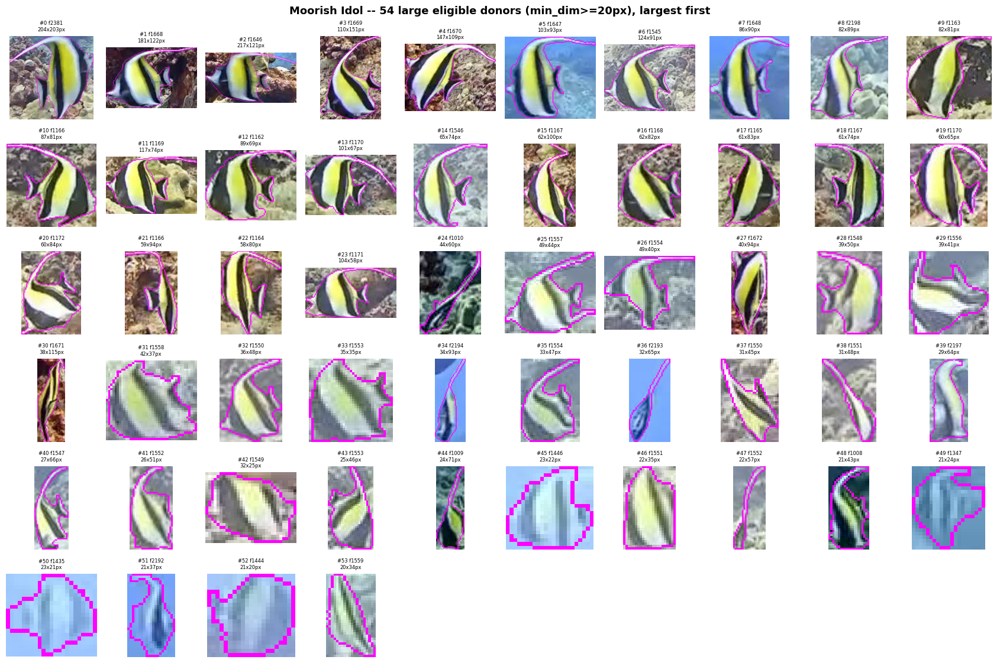

Convict Tang: 31/33 eligible donors kept at min_dim>=20px


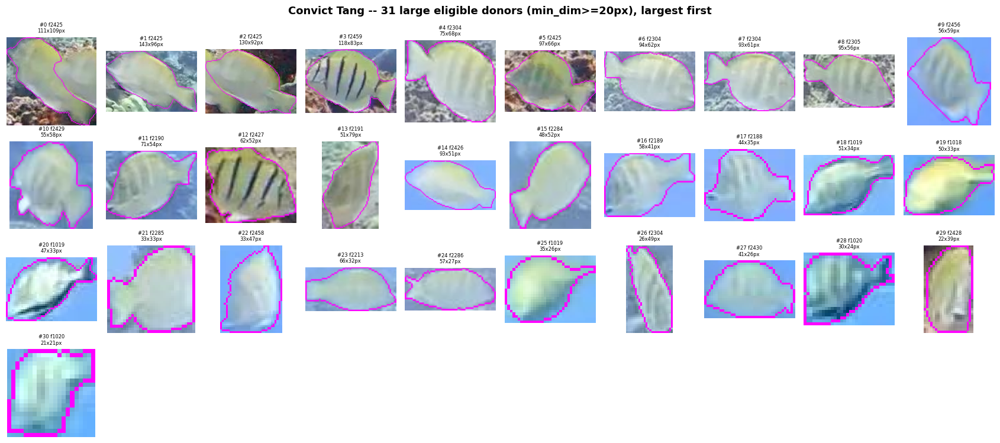

In [2]:
MIN_DIM_LARGE = 20  # px, shorter side of the bbox -- the threshold established for poisson to behave


def donor_gallery(species: str, cols: int = 10, min_dim: int = MIN_DIM_LARGE):
    all_donors = [(n, inst) for n, inst in base.eligible_donors(dataset, species)
                  if dataset[n]["frame"] in frame_index]
    donors = [(n, inst) for n, inst in all_donors
              if min(inst["bbox"][2], inst["bbox"][3]) >= min_dim]
    donors.sort(key=lambda nd: min(nd[1]["bbox"][2], nd[1]["bbox"][3]), reverse=True)
    n = len(donors)
    print(f"{species}: {n}/{len(all_donors)} eligible donors kept at min_dim>={min_dim}px")
    if n == 0:
        print(f"{species}: no local donors at this size")
        return donors

    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.7, rows * 1.9))
    axes = np.atleast_2d(axes)
    for i, (name, inst) in enumerate(donors):
        ax = axes[i // cols][i % cols]
        patch, mask = base.get_donor_patch(dataset, frame_index, name, inst)
        if patch is None:
            ax.axis("off")
            continue
        overlay = base.mask_contour_overlay(patch, mask, 0, 0, thickness=1)
        ax.imshow(overlay)
        w, h = inst["bbox"][2], inst["bbox"][3]
        ax.set_title(f"#{i} f{dataset[name]['frame']}\n{w}x{h}px", fontsize=6)
        ax.axis("off")
    for j in range(n, rows * cols):
        axes[j // cols][j % cols].axis("off")

    fig.suptitle(f"{species} -- {n} large eligible donors (min_dim>={min_dim}px), largest first",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"donor_gallery_{species.replace(' ', '_')}.png", dpi=110)
    plt.show()
    return donors


donor_lists = {}
for sp in SPECIES_LIST:
    donor_lists[sp] = donor_gallery(sp)

## Part 2: Donor augmentation preview

A sample of the large donors above, shown next to their rotate/flip augmented variants --
the SAME transform the pipeline actually applies: a small
continuous-angle rotation (not a 90-degree step -- fish aren't oriented vertically) and an
optional horizontal flip only (no vertical flip -- fish don't swim upside-down). Judge
whether the augmentation itself still reads as a natural pose, separately from whether the
donor itself is good.

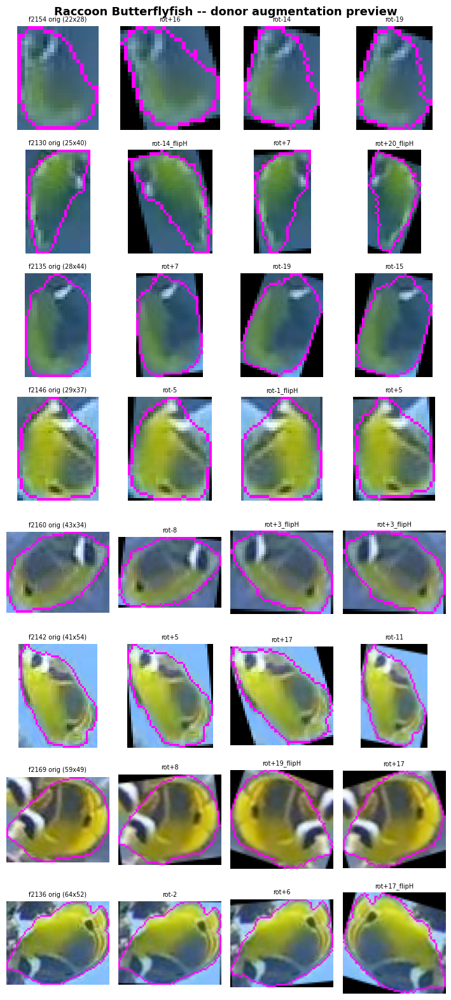

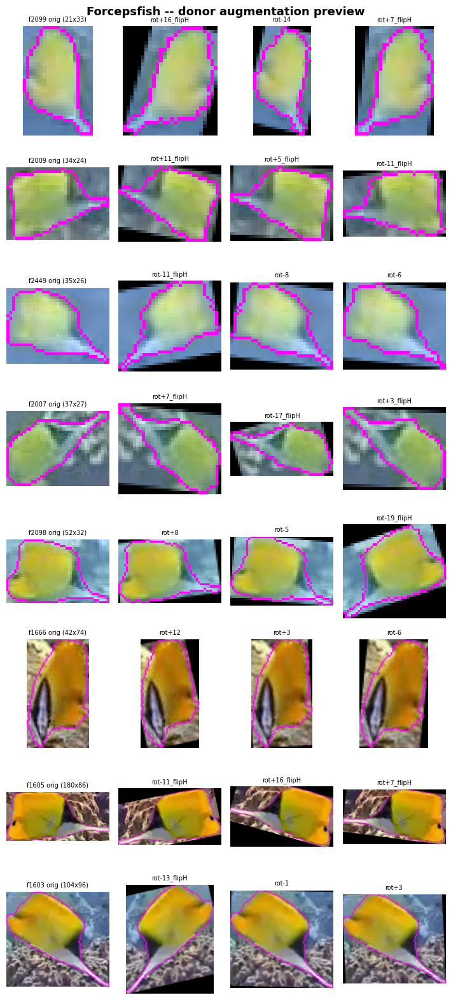

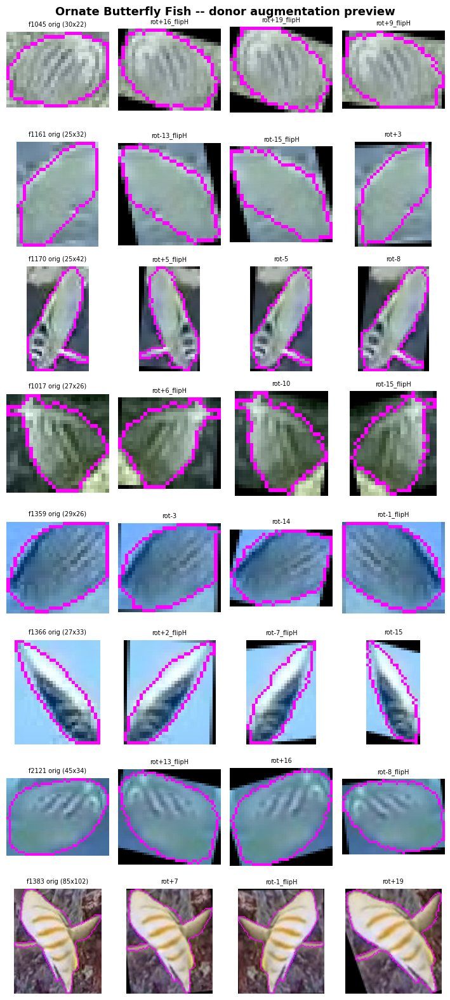

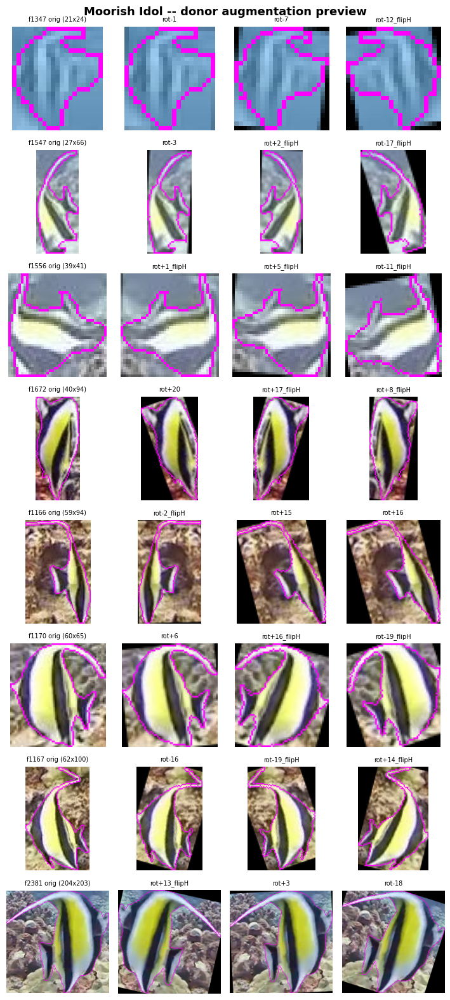

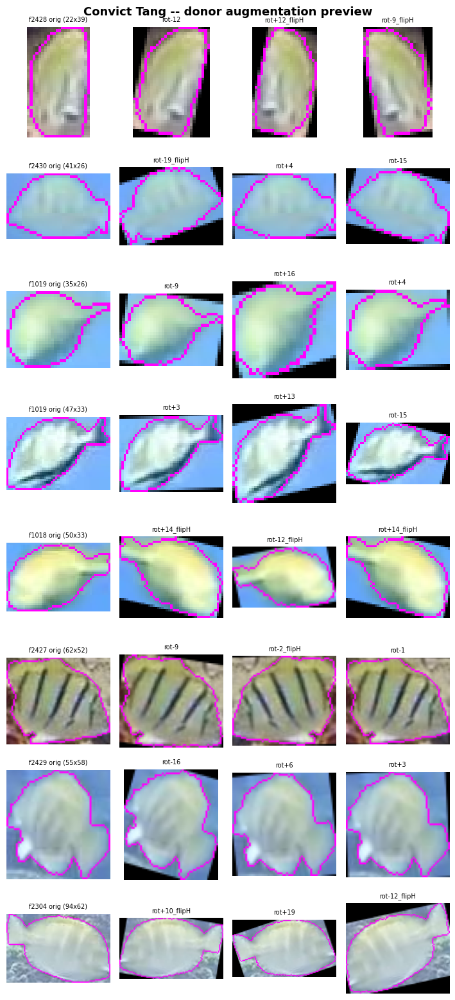

In [3]:
def augmentation_preview(species: str, n_donors: int = 8, n_variants: int = 3, seed: int = 0):
    donors = donor_lists.get(species) or []
    if not donors:
        print(f"{species}: no donors to preview")
        return
    rng = random.Random(f"preview:{seed}:{species}")
    sample = sorted(rng.sample(donors, min(n_donors, len(donors))),
                     key=lambda nd: min(nd[1]["bbox"][2], nd[1]["bbox"][3]))

    cols = n_variants + 1
    fig, axes = plt.subplots(len(sample), cols, figsize=(cols * 1.8, len(sample) * 2.0))
    axes = np.atleast_2d(axes)
    for r, (name, inst) in enumerate(sample):
        patch, mask = base.get_donor_patch(dataset, frame_index, name, inst)
        overlay = base.mask_contour_overlay(patch, mask, 0, 0, thickness=1)
        axes[r][0].imshow(overlay)
        w, h = inst["bbox"][2], inst["bbox"][3]
        axes[r][0].set_title(f"f{dataset[name]['frame']} orig ({w}x{h})", fontsize=7)
        axes[r][0].axis("off")
        for c in range(1, cols):
            p2, m2, tag = random_transform(patch, mask, rng)
            ov2 = base.mask_contour_overlay(p2, m2, 0, 0, thickness=1)
            axes[r][c].imshow(ov2)
            axes[r][c].set_title(tag.strip("_"), fontsize=7)
            axes[r][c].axis("off")

    fig.suptitle(f"{species} -- donor augmentation preview", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"augmentation_preview_{species.replace(' ', '_')}.png", dpi=110)
    plt.show()


for sp in SPECIES_LIST:
    augmentation_preview(sp)

## Part 3: Acceptor / target scenes

Candidate background frames the pipeline could paste onto (the sparse target pool: frames
with <=1 existing instance). Your usable footage (frame >= 1000) covers roughly
18:00:00-19:00:00 real time, with a camera rotation around 18:30 -- sampled here at
roughly one frame per minute across that full hour (not just a handful of 5-minute marks)
so within-view variation (drift, lighting, passing fish, obstructions) is actually visible,
not just the two camera positions themselves. The frame<->time mapping comes from OCR'ing
the footage's own burned-in timestamp overlay, validated against several independent
readings.

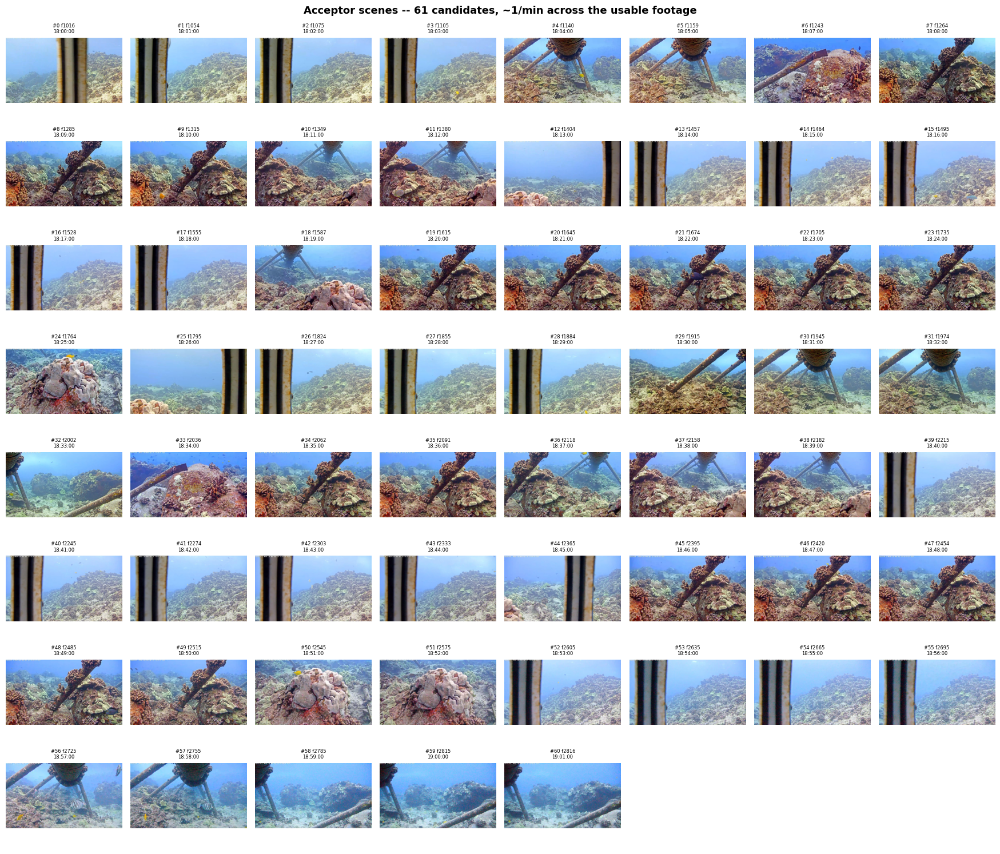

In [4]:
ANCHOR_FRAME = 1240
ANCHOR_MIN = 18 * 60 + 7 + 29 / 60  # 18:07:29 in minutes-of-day
RATE = 30.0  # frames per minute, validated via OCR


def frame_for_minute(total_min: float) -> int:
    return int(round(ANCHOR_FRAME + RATE * (total_min - ANCHOR_MIN)))


def minute_to_hhmm(total_min: float) -> str:
    h = int(total_min // 60)
    m = total_min - h * 60
    mm = int(m)
    ss = int(round((m - mm) * 60))
    return f"{h:02d}:{mm:02d}:{ss:02d}"


def acceptor_gallery(cols: int = 8, step_minutes: float = 1.0):
    # view_filter=False: this is the gallery the keep/drop review was done ON -- filtering it would
    # reshuffle the #indices already reported back.
    targets = base.sparse_target_frames(dataset, frame_index, view_filter=False)
    target_frame_set = {d["frame"]: (n, d) for n, d in targets}

    t = 18 * 60.0
    end_t = 19 * 60.0 + 1
    picks = []
    while t <= end_t:
        wanted = frame_for_minute(t)
        best = None
        for delta in range(0, 60):
            for cand in (wanted - delta, wanted + delta):
                if cand in target_frame_set:
                    best = cand
                    break
            if best is not None:
                break
        if best is not None and (not picks or picks[-1][2] != best):
            name, d = target_frame_set[best]
            picks.append((t, name, best, d))
        t += step_minutes

    n = len(picks)
    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 1.9))
    axes = np.atleast_2d(axes)
    for i, (t, name, fnum, d) in enumerate(picks):
        ax = axes[i // cols][i % cols]
        img = base.get_frame(fnum, frame_index)
        if img is None:
            ax.axis("off")
            continue
        ax.imshow(img)
        ax.set_title(f"#{i} f{fnum}\n{minute_to_hhmm(t)}", fontsize=6)
        ax.axis("off")
    for j in range(n, rows * cols):
        axes[j // cols][j % cols].axis("off")

    fig.suptitle(f"Acceptor scenes -- {n} candidates, ~1/min across the usable footage",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("acceptor_gallery.png", dpi=110)
    plt.show()
    return picks


acceptor_picks = acceptor_gallery()

## Reporting back

- Donors: `"<species> #<index>"` or `"<species> frame <N>"` from Part 1.
- Acceptors: `"#<index>"` from Part 3 (printed in each tile's title, top-left to bottom-right,
  matching `acceptor_picks` below in order).

In [5]:
for i, (t, name, fnum, d) in enumerate(acceptor_picks):
    print(f"#{i}: frame {fnum}, {minute_to_hhmm(t)}")

#0: frame 1016, 18:00:00
#1: frame 1054, 18:01:00
#2: frame 1075, 18:02:00
#3: frame 1105, 18:03:00
#4: frame 1140, 18:04:00
#5: frame 1159, 18:05:00
#6: frame 1243, 18:07:00
#7: frame 1264, 18:08:00
#8: frame 1285, 18:09:00
#9: frame 1315, 18:10:00
#10: frame 1349, 18:11:00
#11: frame 1380, 18:12:00
#12: frame 1404, 18:13:00
#13: frame 1457, 18:14:00
#14: frame 1464, 18:15:00
#15: frame 1495, 18:16:00
#16: frame 1528, 18:17:00
#17: frame 1555, 18:18:00
#18: frame 1587, 18:19:00
#19: frame 1615, 18:20:00
#20: frame 1645, 18:21:00
#21: frame 1674, 18:22:00
#22: frame 1705, 18:23:00
#23: frame 1735, 18:24:00
#24: frame 1764, 18:25:00
#25: frame 1795, 18:26:00
#26: frame 1824, 18:27:00
#27: frame 1855, 18:28:00
#28: frame 1884, 18:29:00
#29: frame 1915, 18:30:00
#30: frame 1945, 18:31:00
#31: frame 1974, 18:32:00
#32: frame 2002, 18:33:00
#33: frame 2036, 18:34:00
#34: frame 2062, 18:35:00
#35: frame 2091, 18:36:00
#36: frame 2118, 18:37:00
#37: frame 2158, 18:38:00
#38: frame 2182, 18:39